# Syllable features under heliox: Fig. 2 A, C, G-J and Supp. Fig. S2

Standardized effects of heliox on the BioSound frequency features (Fig. 2 A, C) and on the full set of 18 BioSound features (Supp. Fig. S2 A, B), and the effects on BioSound spectral entropy, syllable amplitude, syllable duration and inter-syllable interval in both species (Fig. 2 G-J), with all six birds of each species. All effects are Regair - Heliox, so a negative value is an increase under heliox.

Reads one file, `syllable_features_data.pkl`, built by Cells A1 to A6 of `data_figs`. The example spectrograms of Fig. 2 (B, D, E, F) are not made here.

In [2]:
# Cell 1: setup
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import statsmodels
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests

# Paths relative to the repository, so a fresh clone runs without edits (from the repo folder or
# from notebooks/). To use other copies, e.g. on the cluster: export HELIOX_DATA_DIR=/path/to/data/derived
REPO = os.path.dirname(os.getcwd()) if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
DATA_DIR = os.environ.get('HELIOX_DATA_DIR', os.path.join(REPO, 'data'))
FIG_DIR = os.environ.get('HELIOX_FIG_DIR', os.path.join(REPO, 'figures'))
DATA_PATH = os.path.join(DATA_DIR, 'syllable_features_data.pkl')
os.makedirs(FIG_DIR, exist_ok=True)
SAVE_FIGURES = True

plt.rcParams.update({'font.size': 16, 'axes.titlesize': 19, 'axes.labelsize': 17,
                     'xtick.labelsize': 15, 'ytick.labelsize': 15, 'legend.fontsize': 14,
                     'font.family': 'sans-serif', 'svg.fonttype': 'none',   # text stays text in the svg
                     'axes.spines.top': False, 'axes.spines.right': False})

SPECIES = ['zebra_finch', 'starling']
SPECIES_NAME = {'zebra_finch': 'Zebra Finch', 'starling': 'Starling'}
SPECIES_COLOR = {'zebra_finch': 'slategrey', 'starling': 'darkgrey'}

data = pd.read_pickle(DATA_PATH)
for name in ['biosound_zebra_finch', 'biosound_starling', 'timing_zebra_finch', 'timing_starling']:
    table = data[name]
    values = [c for c in table.columns if c not in ('bird', 'condition', 'label')]
    table[values] = table[values].astype(float)       # the BioSound features are stored as float32
    print(f'{name:22s} {len(table):>6d} syllables, {table["bird"].nunique()} birds, '
          f'{(table["condition"] == "regair").sum()} regair / {(table["condition"] == "heliox").sum()} heliox')
print('built', data['meta']['created'], '| statsmodels', statsmodels.__version__)


def save(fig, name):
    if SAVE_FIGURES:
        for ext in ('png', 'pdf'):
            fig.savefig(os.path.join(FIG_DIR, f'{name}.{ext}'), dpi=300, bbox_inches='tight')

biosound_zebra_finch    68392 syllables, 6 birds, 41417 regair / 26975 heliox
biosound_starling       98569 syllables, 6 birds, 76843 regair / 21726 heliox
timing_zebra_finch      63728 syllables, 6 birds, 37130 regair / 26598 heliox
timing_starling         95063 syllables, 6 birds, 73335 regair / 21728 heliox
built 2026-10-11T12:23:35 | statsmodels 0.14.1


In [3]:
# Cell 2: the model used throughout, feature ~ condition + (1 | bird)
def stars(p):
    return '****' if p < 1e-4 else '***' if p < 1e-3 else '**' if p < 1e-2 else '*' if p < 0.05 else 'ns'


def lme_term(formula, d, term, label):
    """Fits a linear mixed-effects model with bird as a random intercept (REML) and returns one fixed
    effect with its SE, Wald z and P, and 95% Wald interval."""
    model = smf.mixedlm(formula, d, groups=d['bird'])
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')        # statsmodels warns while it tries its optimisers in turn
        fit = model.fit(reml=True)
        if not fit.converged or fit.cov_re.iloc[0, 0] <= 0:
            # The gradient optimisers statsmodels tries by default can stop short, or drop the variance
            # between birds to zero, mostly when birds differ little. Powell's method needs no gradient
            # and reaches the optimum in those cases. Both estimates are printed, so the change is visible.
            first, fit = fit, model.fit(reml=True, method=['powell'])
            print(f"  [note] {label}: the default optimisers did not settle (estimate {first.params[term]:.5g}); "
                  f"refit with Powell's method (estimate {fit.params[term]:.5g})")
    low, high = fit.conf_int().loc[term]
    return dict(beta=fit.params[term], se=fit.bse[term], z=fit.tvalues[term], p=fit.pvalues[term],
                ci_low=low, ci_high=high, n=len(d), converged=bool(fit.converged))


def condition_effect(table, feature, label):
    """One feature on the syllables of one species: condition as the fixed effect, coded 1 for regular air
    and 0 for heliox, so the coefficient is Regair - Heliox."""
    d = table[[feature, 'condition', 'bird']].dropna()
    d = d.assign(regair=(d['condition'] == 'regair').astype(float))
    return dict(feature=feature, **lme_term(f'{feature} ~ regair', d, 'regair', label))

In [4]:
# Cell 3: BioSound models, one per feature and species (Fig. 2 A, C; Supp. Fig. S2; Table 1, first three rows)
# feature, label printed in the figures, feature class: listed bottom to top as Supp. Fig. S2 draws them
PAF = pd.DataFrame([
    ('meanS', 'Spectral mean (Hz)', 'spectral'), ('stdS', 'Spectral std (Hz)', 'spectral'),
    ('skewS', 'Spectral skewness', 'spectral'), ('kurtS', 'Spectral kurtosis', 'spectral'),
    ('entS', 'Spectral entropy (0-1)', 'spectral'), ('q1', 'Spectral Q1 (Hz)', 'spectral'),
    ('q2', 'Spectral Q2 (Hz)', 'spectral'), ('q3', 'Spectral Q3 (Hz)', 'spectral'),
    ('meanT', 'Mean time (ms)', 'temporal'), ('stdT', 'Time std (ms)', 'temporal'),
    ('skewT', 'Time skewness', 'temporal'), ('kurtT', 'Time kurtosis', 'temporal'),
    ('entT', 'Time entropy (0-1)', 'temporal'),
    ('sal', 'Pitch saliency', 'fundamental'), ('fund', 'Mean F0 (Hz)', 'fundamental'),
    ('minfund', 'Min. F0 (Hz)', 'fundamental'), ('maxfund', 'Max. F0 (Hz)', 'fundamental'),
    ('F1', 'First Formant (Hz)', 'fundamental')], columns=['feature', 'label', 'feature_class'])

rows = []
for species in SPECIES:
    table = data[f'biosound_{species}']
    for feature in PAF['feature']:
        row = condition_effect(table, feature, f'{species} {feature}')
        # Features come in Hz, in seconds or without a unit, so each effect is divided by the SD of the
        # feature over all of the species' syllables (both conditions, all birds) to put them on one scale.
        sd = table[feature].std(ddof=1)
        row.update(species=species, pooled_sd=sd, beta_std=row['beta'] / sd,
                   ci_low_std=row['ci_low'] / sd, ci_high_std=row['ci_high'] / sd, sig=stars(row['p']))
        rows.append(row)
paf_stats = pd.DataFrame(rows).merge(PAF, on='feature')
# Benjamini-Hochberg across the 18 features of a species
paf_stats['q_bh'] = paf_stats.groupby('species')['p'].transform(lambda p: multipletests(p, method='fdr_bh')[1])

if not paf_stats['converged'].all():
    print('[CHECK] not converged:', paf_stats.loc[~paf_stats['converged'], ['species', 'feature']].to_dict('records'))
show = paf_stats.set_index(['species', 'feature']).loc[[(s, f) for s in SPECIES for f in PAF['feature'][::-1]]]
print(show[['beta', 'se', 'z', 'p', 'q_bh', 'sig', 'beta_std', 'n']].to_string(
    formatters={'beta': '{:.4f}'.format, 'se': '{:.4f}'.format, 'z': '{:.2f}'.format, 'p': '{:.2g}'.format,
                'q_bh': '{:.2g}'.format, 'beta_std': '{:.4f}'.format}))

  [note] starling kurtT: the default optimisers did not settle (estimate 0.15213); refit with Powell's method (estimate 0.15212)
                         beta      se      z        p     q_bh   sig beta_std      n
species     feature                                                                 
zebra_finch F1      -128.8033  2.0417 -63.09        0        0  ****  -0.4717  68392
            maxfund  -64.7213 10.1553  -6.37  1.9e-10  2.6e-10  ****  -0.0490  68392
            minfund   15.4277  3.2403   4.76  1.9e-06  2.5e-06  ****   0.0365  68392
            fund    -110.1137  6.2456 -17.63  1.4e-69  3.2e-69  ****  -0.1383  68392
            sal        0.0107  0.0008  13.96  2.8e-44    5e-44  ****   0.0935  68392
            entT       0.0024  0.0002  12.46  1.3e-35  1.9e-35  ****   0.0955  68392
            kurtT     -0.0094  0.0041  -2.26    0.024    0.027     *  -0.0167  68385
            skewT     -0.0127  0.0029  -4.31  1.7e-05    2e-05  ****  -0.0306  68385
            stdT     

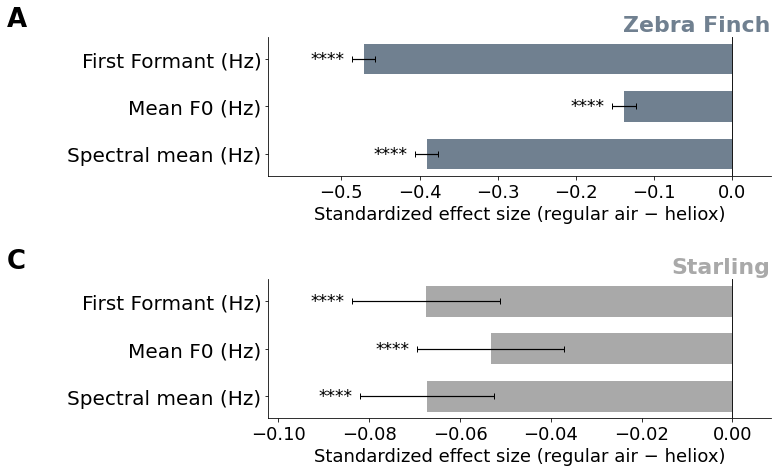

In [5]:
# Cell 4: Fig. 2 A, C. Standardized effects on the three frequency features
def effect_bars(ax, s, colors, star_size):
    """Horizontal bars of the standardized effect with its 95% interval and significance stars."""
    y = np.arange(len(s))
    ax.barh(y, s['beta_std'], color=colors, height=0.65, zorder=3)
    ax.errorbar(s['beta_std'], y, xerr=[s['beta_std'] - s['ci_low_std'], s['ci_high_std'] - s['beta_std']],
                fmt='none', ecolor='black', elinewidth=1.2, capsize=3, zorder=4)
    ax.axvline(0, color='black', lw=0.9, zorder=5)
    ax.set_yticks(y)
    ax.set_yticklabels(s['label'])
    gap = 0.02 * (max(s['ci_high_std'].max(), 0) - min(s['ci_low_std'].min(), 0))
    for yi, r in zip(y, s.itertuples()):
        # stars sit beyond the far end of the interval, on the side the bar points to
        if r.beta_std >= 0:
            ax.text(r.ci_high_std + gap, yi, r.sig, va='center', ha='left', fontsize=star_size)
        else:
            ax.text(r.ci_low_std - gap, yi, r.sig, va='center', ha='right', fontsize=star_size)


FREQUENCY = ['meanS', 'fund', 'F1']            # bottom to top
fig, axes = plt.subplots(2, 1, figsize=(9, 7), gridspec_kw=dict(hspace=0.75))
for ax, species, letter in zip(axes, SPECIES, 'AC'):
    s = paf_stats[paf_stats['species'] == species].set_index('feature').loc[FREQUENCY]
    effect_bars(ax, s, SPECIES_COLOR[species], star_size=17)
    left, right = min(s['ci_low_std'].min(), 0), max(s['ci_high_std'].max(), 0)
    # room for the stars on whichever side has bars
    ax.set_xlim(left - 0.22 * (right - left), right + (0.22 if right > 0 else 0.1) * (right - left))
    ax.tick_params(axis='y', labelsize=20)
    ax.tick_params(axis='x', labelsize=18)
    ax.set_xlabel('Standardized effect size (regular air − heliox)', fontsize=18)
    ax.set_title(SPECIES_NAME[species], loc='right', color=SPECIES_COLOR[species], fontsize=22, fontweight='bold')
    ax.text(-0.52, 1.08, letter, transform=ax.transAxes, fontsize=26, fontweight='bold')
save(fig, 'fig2_AC_frequency_features')
plt.show()

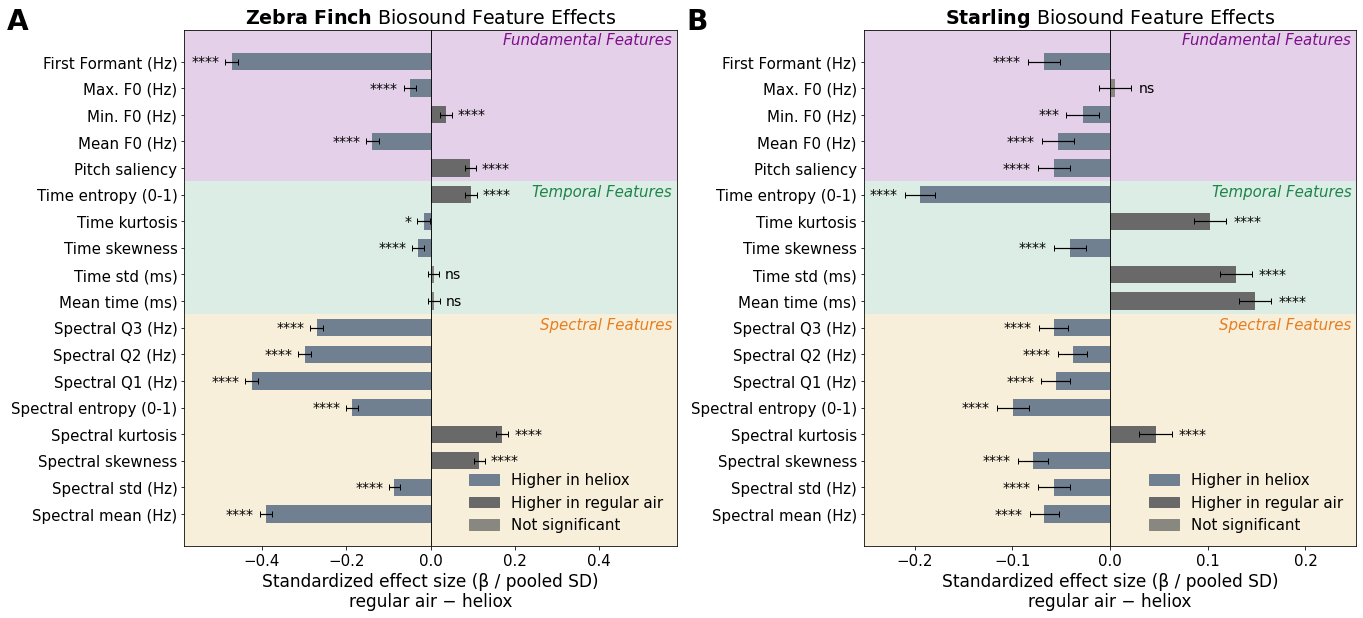

In [6]:
# Cell 5: Supp. Fig. S2 A, B. Standardized effects on all 18 BioSound features
BAND = {'spectral': ('#F7EFD9', '#E67E22', 'Spectral Features'),          # band colour, label colour, label
        'temporal': ('#DCEDE5', '#1E8449', 'Temporal Features'),
        'fundamental': ('#E4D0E8', '#7D0F8C', 'Fundamental Features')}
BAR = {'heliox': 'slategrey', 'regair': 'dimgray', 'ns': '#888780'}

fig, axes = plt.subplots(1, 2, figsize=(21, 9.5), gridspec_kw=dict(wspace=0.38))
for ax, species, letter in zip(axes, SPECIES, 'AB'):
    s = paf_stats[paf_stats['species'] == species].set_index('feature').loc[PAF['feature']]
    colors = [BAR['ns'] if r.sig == 'ns' else BAR['heliox'] if r.beta_std < 0 else BAR['regair']
              for r in s.itertuples()]
    effect_bars(ax, s, colors, star_size=14)
    # symmetric limits, so that the two directions can be compared by eye
    reach = 1.2 * max(abs(s['ci_low_std'].min()), abs(s['ci_high_std'].max()))
    ax.set_xlim(-reach, reach)
    ax.set_ylim(-1.2, len(s) + 0.2)
    position = pd.Series(np.arange(len(s)), index=s['feature_class'].to_numpy())
    for name, (band, ink, text) in BAND.items():
        bottom = -1.2 if position[name].min() == 0 else position[name].min() - 0.5
        top = len(s) + 0.2 if position[name].max() == len(s) - 1 else position[name].max() + 0.5
        ax.axhspan(bottom, top, color=band, zorder=0, lw=0)
        ax.text(0.99, top - 0.12, text, transform=ax.get_yaxis_transform(), ha='right', va='top',
                color=ink, fontsize=15, style='italic')
    ax.legend(handles=[mpatches.Patch(color=BAR['heliox'], label='Higher in heliox'),
                       mpatches.Patch(color=BAR['regair'], label='Higher in regular air'),
                       mpatches.Patch(color=BAR['ns'], label='Not significant')],
              loc='lower right', frameon=False, fontsize=15)
    ax.spines['top'].set_visible(True)
    ax.spines['right'].set_visible(True)
    ax.set_xlabel('Standardized effect size (β / pooled SD)\nregular air − heliox')
    ax.set_title(r'$\mathbf{' + SPECIES_NAME[species].replace(' ', r'\ ') + '}$ Biosound Feature Effects')
    ax.text(-0.36, 1.0, letter, transform=ax.transAxes, fontsize=28, fontweight='bold')
save(fig, 'suppfig_S2_biosound_features')
plt.show()

In [7]:
# Cell 6: models for Fig. 2 G-J (spectral entropy, amplitude, duration, ISI; Table 1, last two rows)
# One model per feature fit on both species, feature ~ condition * species + (1 | bird), all six birds of each
# species. The Regair - Heliox effect in each species, and the difference between the species (the brackets),
# are sums of its fixed effects.
# Panel G is BioSound spectral entropy (entS, 0 to 1, from the power spectrum of the syllable). It replaces the
# 'spectral_entropy' column of the feature tables, which was the entropy of the spectrogram averaged over
# frequency, so a measure of how energy is spread over time within the padded syllable rather than over frequency.
from scipy.stats import norm

TIMING = ['entS', 'level_db', 'duration', 'isi']         # panels G, H, I, J


def plausible(table):
    """Drops syllables whose duration is outside (0, 2] s or whose ISI is outside [0, 2] s, the plausibility
    limits of the original analysis. Syllables with no ISI stay, and enter every model except the
    ISI one."""
    ok = table['duration'].isna() | ((table['duration'] > 0) & (table['duration'] <= 2.0))
    return table[ok & (table['isi'].isna() | ((table['isi'] >= 0) & (table['isi'] <= 2.0)))]


def regair_or_heliox(table):
    """The BioSound syllables recorded as regair or heliox. Fig. 2 A, C and Supp. Fig. S2 count every label
    without 'heliox' in it as regair (regairb, transition); here they are left out, as in panels H-J."""
    if 'label' not in table.columns:
        raise KeyError("the BioSound tables have no 'label' column: rerun Cells A1 to A6 of data_figs "
                       '(A2 now keeps the label as recorded)')
    return table[table['label'].isin(['regair', 'heliox'])]


def joint_effects(tables, feature, version):
    """The Regair - Heliox effect in each species and the difference between them, from one model.
    Fit with statsmodels' default optimisers, as for the published figure; a fit that did not converge
    is marked in the converged column."""
    d = pd.concat([tables[sp][[feature, 'condition', 'bird']].assign(starling=float(sp == 'starling'))
                   for sp in SPECIES], ignore_index=True).dropna()
    d = d.assign(regair=(d['condition'] == 'regair').astype(float))
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        fit = smf.mixedlm(f'{feature} ~ regair * starling', d, groups=d['bird']).fit(reml=True)
    b = fit.fe_params
    V = fit.cov_params().loc[b.index, b.index]
    rows = []
    for species, terms in [('zebra_finch', ['regair']), ('starling', ['regair', 'regair:starling']),
                           ('difference', ['regair:starling'])]:
        L = pd.Series(1.0, index=terms).reindex(b.index).fillna(0.0)
        beta, se = float(L @ b), float(np.sqrt(L @ V @ L))
        p = 2 * norm.sf(abs(beta / se))
        in_model = d if species == 'difference' else d[d['starling'] == float(species == 'starling')]
        rows.append(dict(version=version, feature=feature, species=species, beta=beta, se=se, z=beta / se, p=p,
                         ci_low=beta - 1.959964 * se, ci_high=beta + 1.959964 * se, sig=stars(p),
                         n=len(in_model), n_birds=in_model['bird'].nunique(), converged=bool(fit.converged)))
    return rows


timing = {sp: plausible(data[f'timing_{sp}']) for sp in SPECIES}
biosound = {sp: regair_or_heliox(data[f'biosound_{sp}']) for sp in SPECIES}
print('panels H-J: ' + ', '.join(f'{sp} {len(t)} syllables from {t["bird"].nunique()} birds' for sp, t in timing.items()))
print('panel G:    ' + ', '.join(f'{sp} {len(t)} syllables from {t["bird"].nunique()} birds' for sp, t in biosound.items()))

timing_effects = pd.DataFrame([row for feature in TIMING
                               for row in joint_effects(biosound if feature == 'entS' else timing, feature, 'all birds')])
timing_stats = timing_effects[timing_effects['species'].isin(SPECIES)]                  # the points of Fig. 2 G-J
interaction = timing_effects[timing_effects['species'] == 'difference'].set_index('feature')   # the brackets

numbers = {'beta': '{:.4f}'.format, 'se': '{:.4f}'.format, 'z': '{:.2f}'.format, 'p': '{:.2g}'.format}
print('\nFig. 2 G-J: Regair - Heliox per species, and the species difference')
print(timing_effects.set_index(['feature', 'species'])[['beta', 'se', 'z', 'p', 'sig', 'n', 'n_birds', 'converged']]
      .to_string(formatters=numbers))

panels H-J: zebra_finch 63724 syllables from 6 birds, starling 93962 syllables from 6 birds
panel G:    zebra_finch 64171 syllables from 6 birds, starling 95032 syllables from 6 birds

Fig. 2 G-J: Regair - Heliox per species, and the species difference
                        beta     se      z        p   sig       n  n_birds  converged
feature  species                                                                     
entS     zebra_finch -0.0178 0.0008 -23.43   2e-121  ****   64171        6       True
         starling    -0.0109 0.0008 -13.66  1.7e-42  ****   95032        6       True
         difference   0.0069 0.0011   6.27  3.6e-10  ****  159203       12       True
level_db zebra_finch  0.7486 0.0606  12.35  4.8e-35  ****   63724        6       True
         starling     2.7807 0.0639  43.52        0  ****   93962        6       True
         difference   2.0321 0.0881  23.08 8.2e-118  ****  157686       12       True
duration zebra_finch -0.0002 0.0022  -0.08     0.94    ns  

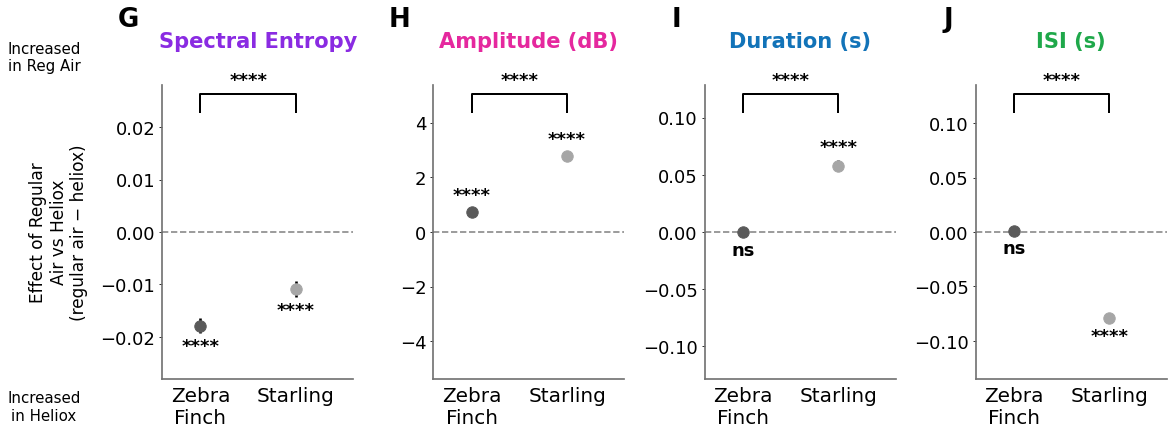

In [8]:
# Cell 7: Fig. 2 G-J. Regair - Heliox effect per species, with its 95% interval
PANEL = {'entS': ('G', 'Spectral Entropy', '#8A2BE2'), 'level_db': ('H', 'Amplitude (dB)', '#E5289E'),
         'duration': ('I', 'Duration (s)', '#1273B8'), 'isi': ('J', 'ISI (s)', '#1FA84A')}
POINT_COLOR = {'zebra_finch': '#5A5A5A', 'starling': '#A6A6A6'}


def effect_points(stats, brackets, letters=True):
    """Four panels: each species' effect with its 95% interval, and the species difference as a bracket."""
    fig, axes = plt.subplots(1, 4, figsize=(18, 5.4), gridspec_kw=dict(wspace=0.42))
    for ax, feature in zip(axes, TIMING):
        letter, title, ink = PANEL[feature]
        est = stats[stats['feature'] == feature].set_index('species').loc[SPECIES]
        ax.axhline(0, ls='--', lw=1.7, color='0.55', zorder=1)
        for x, r in enumerate(est.itertuples()):
            ax.vlines(x, r.ci_low, r.ci_high, color='black', lw=2.6, zorder=2)
            ax.scatter(x, r.beta, s=130, color=POINT_COLOR[r.Index], zorder=3)
            # a significant positive effect is labelled above its interval, anything else below it,
            # which keeps the labels clear of the bracket
            above = r.beta > 0 and r.sig != 'ns'
            ax.annotate(r.sig, xy=(x, r.ci_high if above else r.ci_low), xytext=(0, 4 if above else -4),
                        textcoords='offset points', ha='center', va='bottom' if above else 'top',
                        fontsize=18, fontweight='bold')
        # limits as in the paper: zero in the middle of every panel, and room above the data for the bracket
        pad = 0.22 * (est['ci_high'].max() - est['ci_low'].min())
        half = 1.3 * max(max(est['ci_high'].max(), 0) + 2.45 * pad, abs(est['ci_low'].min() - pad))
        ax.set_ylim(-half, half)
        ax.set_xlim(-0.4, 1.6)
        ax.set_xticks([0, 1])
        ax.set_xticklabels(['Zebra\nFinch', 'Starling'], fontsize=20)
        ax.tick_params(axis='y', labelsize=18)
        ax.tick_params(axis='x', length=0, pad=8)
        for side in ('left', 'bottom'):
            ax.spines[side].set_linewidth(1.7)
            ax.spines[side].set_color('0.45')
        # bracket: the species difference, drawn at a fixed height (x in data units, y in axes units)
        across = ax.get_xaxis_transform()
        ax.plot([0, 0, 1, 1], [0.91, 0.97, 0.97, 0.91], transform=across, color='black', lw=2, clip_on=False)
        ax.text(0.5, 0.985, brackets.loc[feature, 'sig'], transform=across, ha='center', va='bottom',
                fontsize=18, fontweight='bold')
        ax.set_title(title, color=ink, fontweight='bold', fontsize=21, pad=38)
        if letters:
            ax.text(-0.12, 1.2, letter, transform=ax.transAxes, fontsize=26, fontweight='bold', ha='right')
    axes[0].set_ylabel('Effect of Regular\nAir vs Heliox\n(regular air − heliox)', fontsize=17, labelpad=12)
    axes[0].text(-0.62, 1.04, 'Increased\nin Reg Air', transform=axes[0].transAxes, ha='center', va='bottom', fontsize=15)
    axes[0].text(-0.62, -0.04, 'Increased\nin Heliox', transform=axes[0].transAxes, ha='center', va='top', fontsize=15)
    return fig


fig = effect_points(timing_stats, interaction)
save(fig, 'fig2_GJ_entropy_amplitude_duration_isi')
plt.show()

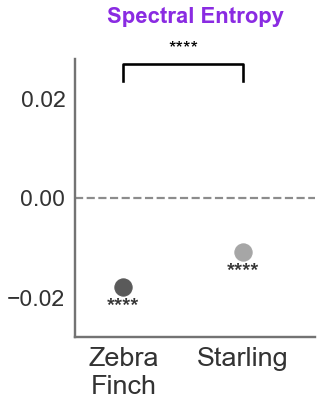

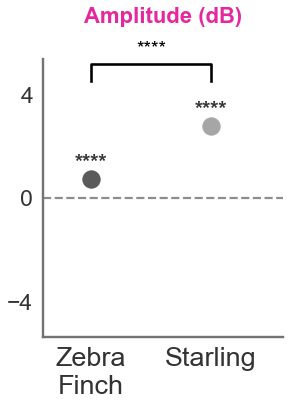

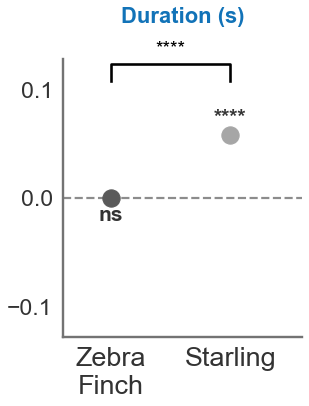

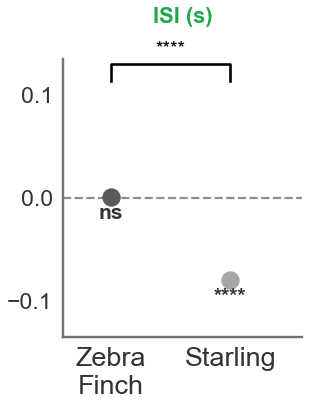

In [9]:
# Cell 7b: Fig. 2 G-J as four separate figures, without panel letters
# Drawn to match the single panels of the published figure: the same shape (axes a little taller than wide),
# no y-axis label, grey axes without tick marks, and three or four round y ticks. Run after Cells 6 and 7.
from matplotlib.ticker import MaxNLocator

INK = '#333333'          # tick labels
# Arial, as in the published panels, where it is installed; otherwise the closest sans-serif font
FONTS = {'font.family': 'sans-serif', 'font.sans-serif': ['Arial', 'Helvetica', 'Liberation Sans', 'DejaVu Sans']}


def effect_panel(feature, stats, brackets):
    title, color = PANEL[feature][1:]
    est = stats[stats['feature'] == feature].set_index('species').loc[SPECIES]
    fig = plt.figure(figsize=(4.8, 7.5))
    # axes placed by hand (left, bottom, width, height as fractions of the figure), so every feature
    # gives a figure of exactly the same shape whatever the width of its tick labels
    ax = fig.add_axes([0.154, 0.2725, 0.693, 0.515])
    ax.axhline(0, ls='--', lw=2.2, color='0.55', zorder=1)
    for x, r in enumerate(est.itertuples()):
        ax.vlines(x, r.ci_low, r.ci_high, color='black', lw=4.5, zorder=2)
        ax.scatter(x, r.beta, s=300, color=POINT_COLOR[r.Index], zorder=3)
        # a significant positive effect is labelled above its interval, anything else below it,
        # which keeps the labels clear of the bracket
        above = r.beta > 0 and r.sig != 'ns'
        ax.annotate(r.sig, xy=(x, r.ci_high if above else r.ci_low), xytext=(0, 3 if above else -3),
                    textcoords='offset points', ha='center', va='bottom' if above else 'top',
                    fontsize=21, fontweight='bold', color=INK)
    # limits as in Cell 7: zero in the middle, and room above the data for the bracket
    pad = 0.22 * (est['ci_high'].max() - est['ci_low'].min())
    half = 1.3 * max(max(est['ci_high'].max(), 0) + 2.45 * pad, abs(est['ci_low'].min() - pad))
    ax.set_ylim(-half, half)
    ax.yaxis.set_major_locator(MaxNLocator(nbins=3, symmetric=True))
    ax.set_xlim(-0.4, 1.6)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Zebra\nFinch', 'Starling'], fontsize=27, color=INK)
    ax.tick_params(axis='y', labelsize=23, labelcolor=INK, length=0, pad=10)
    ax.tick_params(axis='x', length=0, pad=10)
    for side in ('left', 'bottom'):
        ax.spines[side].set_linewidth(2.4)
        ax.spines[side].set_color('0.45')
    # bracket: the species difference, drawn at a fixed height (x in data units, y in axes units)
    across = ax.get_xaxis_transform()
    ax.plot([0, 0, 1, 1], [0.92, 0.98, 0.98, 0.92], transform=across, color='black', lw=2.6, clip_on=False)
    ax.text(0.5, 1.005, brackets.loc[feature, 'sig'], transform=across, ha='center', va='bottom',
            fontsize=19, color='black')
    ax.set_title(title, color=color, fontweight='bold', fontsize=22, pad=36)
    return fig


# the font is looked up when the figure is drawn, so drawing, saving and showing all happen inside FONTS
with plt.rc_context(FONTS):
    for feature in TIMING:
        fig = effect_panel(feature, timing_stats, interaction)
        save(fig, f'fig2_{feature}_effect')       # fig2_entS_effect, fig2_level_db_effect, ...
        plt.show()
        plt.close(fig)

In [10]:
print(data['timing_starling'].groupby('bird').size())

bird
s_b1349h_23    12683
s_b1354_25     17338
s_b1364h_25    49755
s_b1481h_24     2336
s_b1484h_24     6928
s_b1556h_24     6023
dtype: int64


In [11]:
# Cell 9: bird-weighted check of Fig. 2 G-J
# Why this cell: the Fig. 2 G-J models are fit to every syllable, and one starling supplies about half
# of the starling syllables, so the starling estimates follow that bird. Here every bird counts once:
# each bird's own Regair - Heliox difference of means is computed first, and the six differences per
# species are tested against zero (one-sample t-test, 5 df). The species difference is a Welch t-test
# on the two sets of six. Printed beside the syllable-level estimates from Cell 6. Nothing is saved.
# Run after Cell 7 (it reads timing, biosound, timing_effects and PANEL).
from scipy import stats as sps

UNIT = {'entS': (1.0, ''), 'level_db': (1.0, 'dB'), 'duration': (1e3, 'ms'), 'isi': (1e3, 'ms')}
syllable_level = timing_effects.set_index(['feature', 'species'])

for feature in TIMING:
    tables = biosound if feature == 'entS' else timing
    scale, unit = UNIT[feature]
    digits = 4 if feature == 'entS' else 2
    print(f"\nFig. 2{PANEL[feature][0]}  {PANEL[feature][1]}  (Regair - Heliox{', ' + unit if unit else ''})")
    per_bird = {}
    for sp in SPECIES:
        # one mean per bird and condition, then the difference within bird
        means = tables[sp].groupby(['bird', 'condition'])[feature].mean().unstack('condition')
        d = ((means['regair'] - means['heliox']) * scale).dropna()
        per_bird[sp] = d
        t, p = sps.ttest_1samp(d, 0.0)
        model = syllable_level.loc[(feature, sp), 'beta'] * scale
        same = int((np.sign(d) == np.sign(model)).sum())
        print(f"  {SPECIES_NAME[sp]:11s} birds: " + '  '.join(f'{v:.{digits}f}' for v in d.sort_values()))
        print(f"  {'':11s} mean of birds {d.mean():.{digits}f}, t({len(d) - 1}) = {t:.2f}, P = {p:.3g} ({stars(p)}); "
              f"{same}/{len(d)} birds agree with the syllable-level estimate {model:.{digits}f} "
              f"({syllable_level.loc[(feature, sp), 'sig']})")
    t, p = sps.ttest_ind(per_bird['zebra_finch'], per_bird['starling'], equal_var=False)
    print(f"  species difference (Welch): t = {t:.2f}, P = {p:.3g} ({stars(p)}); "
          f"syllable-level bracket: {syllable_level.loc[(feature, 'difference'), 'sig']}")


Fig. 2G  Spectral Entropy  (Regair - Heliox)
  Zebra Finch birds: -0.0633  -0.0322  -0.0251  -0.0170  -0.0128  -0.0104
              mean of birds -0.0268, t(5) = -3.35, P = 0.0204 (*); 6/6 birds agree with the syllable-level estimate -0.0178 (****)
  Starling    birds: -0.0379  -0.0270  -0.0086  0.0019  0.0031  0.0104
              mean of birds -0.0097, t(5) = -1.25, P = 0.267 (ns); 3/6 birds agree with the syllable-level estimate -0.0109 (****)
  species difference (Welch): t = -1.54, P = 0.155 (ns); syllable-level bracket: ****

Fig. 2H  Amplitude (dB)  (Regair - Heliox, dB)
  Zebra Finch birds: -0.69  -0.63  1.33  1.64  1.75  1.98
              mean of birds 0.90, t(5) = 1.80, P = 0.132 (ns); 4/6 birds agree with the syllable-level estimate 0.75 (****)
  Starling    birds: 0.20  1.84  2.47  3.15  4.18  4.49
              mean of birds 2.72, t(5) = 4.20, P = 0.00852 (**); 6/6 birds agree with the syllable-level estimate 2.78 (****)
  species difference (Welch): t = -2.23, P = 0.05